# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [122]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [123]:
aviation_data = pd.read_csv('C:/Users/user/OneDrive/Desktop/Data analysis Jet Airline Safety/dsc-course0-m8-lab/data/CleanedAviationData.csv', encoding='latin-1')

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [124]:
aviation_data['Plane.Type'] = np.where(aviation_data['Total.Passengers'] >= 20, 'Larger airplane', 'Smaller airplane') 

In [125]:
aviation_data.head()

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Country,Injury.Severity,Aircraft.damage,Registration.Number,Make,Model,...,Report.Status,Publication.Date,City,State,Total.Passengers.Injured,Total.Fatal.&.Serious.Injuries,Total.Passengers,Total.Serious.Injuries.Percentage,Total.Fatal.&.Serious.Injuries.Percentage,Plane.Type
0,20001214X42040,Accident,LAX83LA093,1983,UNITED STATES,Non-Fatal,UNKNOWN,N84US,PICCARD,AX-6,...,Probable Cause,NaN,Arroyo grande,CA,2,1,3,33.333333,33.333333,Smaller airplane
1,20001214X42095,Accident,SEA83LA036,1983,UNITED STATES,Non-Fatal,SUBSTANTIAL,N1296M,CESSNA,182P,...,Probable Cause,NaN,Newport,OR,4,0,7,0.000000,0.000000,Smaller airplane
2,20001214X42067,Accident,MKC83LA056,1983,UNITED STATES,Non-Fatal,SUBSTANTIAL,N2639C,CESSNA,182RG,...,Probable Cause,NaN,Woodbine,IA,2,0,4,0.000000,0.000000,Smaller airplane
3,20001214X42063,Accident,MKC83LA050,1983,UNITED STATES,Non-Fatal,SUBSTANTIAL,N58664,CESSNA,182P,...,Probable Cause,NaN,Maryville,MO,1,0,2,0.000000,0.000000,Smaller airplane
4,20001214X42018,Accident,LAX83FUG11,1983,UNITED STATES,Non-Fatal,SUBSTANTIAL,N3084R,PIPER,PA-28R-200,...,Probable Cause,NaN,Upland,CA,2,0,2,0.000000,0.000000,Smaller airplane


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

Make
1977 COLFER-CHAN             0.0
2003 NASH                    0.0
2007 SAVAGE AIR LLC          0.0
2021FX3 LLC                  0.0
5 RIVERS LLC                 0.0
67 FLYING DUTCHMAN           0.0
A PAIR OF JACKS              0.0
A. H. GETTINGS               0.0
A. LE FRANCOIS               0.0
AAA AIRCRAFT LLC             0.0
AARDEMA ROBERT JOHN          0.0
ABBOTT                       0.0
ABC                          0.0
ABRAHAM J G II/ERICKSON K    0.0
ABRAMS/NUDING                0.0
Name: Total.Fatal.&.Serious.Injuries.Percentage, dtype: float64
Make
737                               0.0
AERO COMMANDER                    0.0
AEROSPACE                         0.0
AIRBUS INDUSTRIES                 0.0
AMERICAN BLIMP CORP.              0.0
AVIAN BALLOON                     0.0
BAC-AEROSPATIALE                  0.0
BAE                               0.0
BALLOON WORKS INC                 0.0
BOEING - CANADA (DE HAVILLAND)    0.0
BOEING OF CANADA/DEHAV DIV        0.0
BOEING VERTOL

C:\Users\user\AppData\Local\Temp\ipykernel_54168\2890029024.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot( x=larger_plane_sizes_means.index, y=larger_plane_sizes_means.values, ax = axes[0], palette='Blues')
C:\Users\user\AppData\Local\Temp\ipykernel_54168\2890029024.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot( x=smaller_plane_sizes_means.index, y=smaller_plane_sizes_means.values, ax = axes[1], palette='Reds')


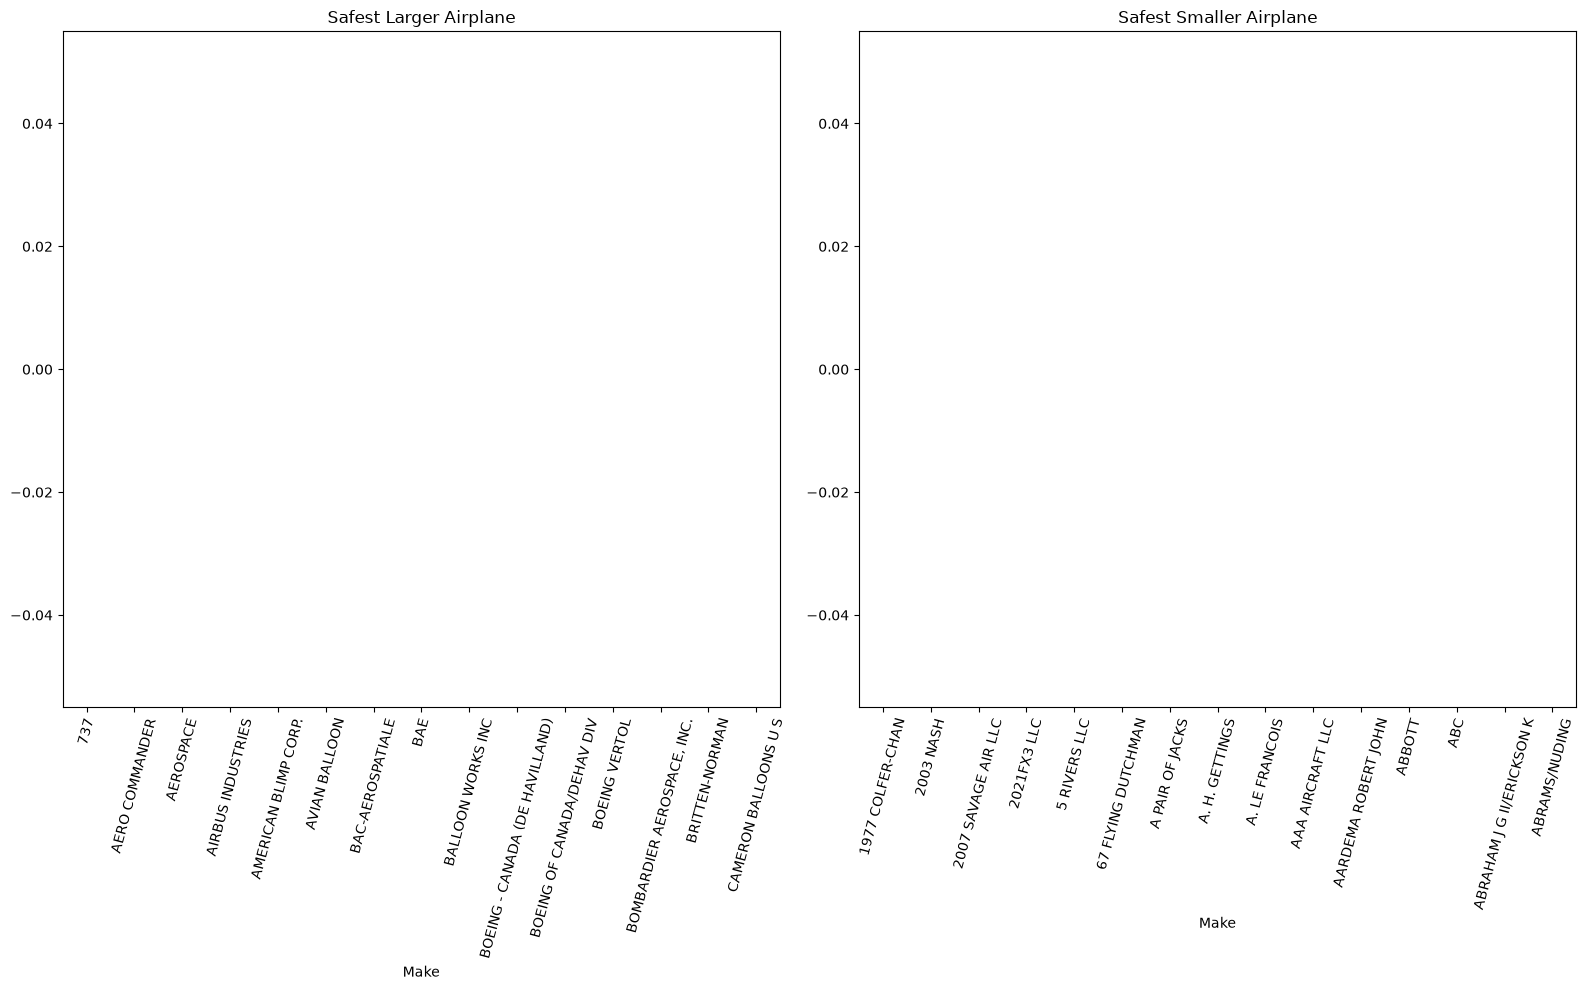

In [126]:
smaller_plane_sizes_means = aviation_data[aviation_data['Plane.Type'] == 'Smaller airplane']
smaller_plane_sizes_means = smaller_plane_sizes_means.groupby('Make')['Total.Fatal.&.Serious.Injuries.Percentage'].mean().nsmallest(15)
print(smaller_plane_sizes_means)

larger_plane_sizes_means = aviation_data[aviation_data['Plane.Type'] == 'Larger airplane']
larger_plane_sizes_means = larger_plane_sizes_means.groupby('Make')['Total.Fatal.&.Serious.Injuries.Percentage'].mean().nsmallest(15)
print(larger_plane_sizes_means)

figs, axes = plt.subplots(1,2, figsize=(16,10))

sns.barplot( x=larger_plane_sizes_means.index, y=larger_plane_sizes_means.values, ax = axes[0], palette='Blues')
sns.barplot( x=smaller_plane_sizes_means.index, y=smaller_plane_sizes_means.values, ax = axes[1], palette='Reds')

axes[0].set_title('Safest Larger Airplane')
axes[0].tick_params(axis='x', rotation=75)

axes[1].set_title('Safest Smaller Airplane')
axes[1].tick_params(axis='x', rotation=75)

plt.tight_layout()
plt.show()



**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

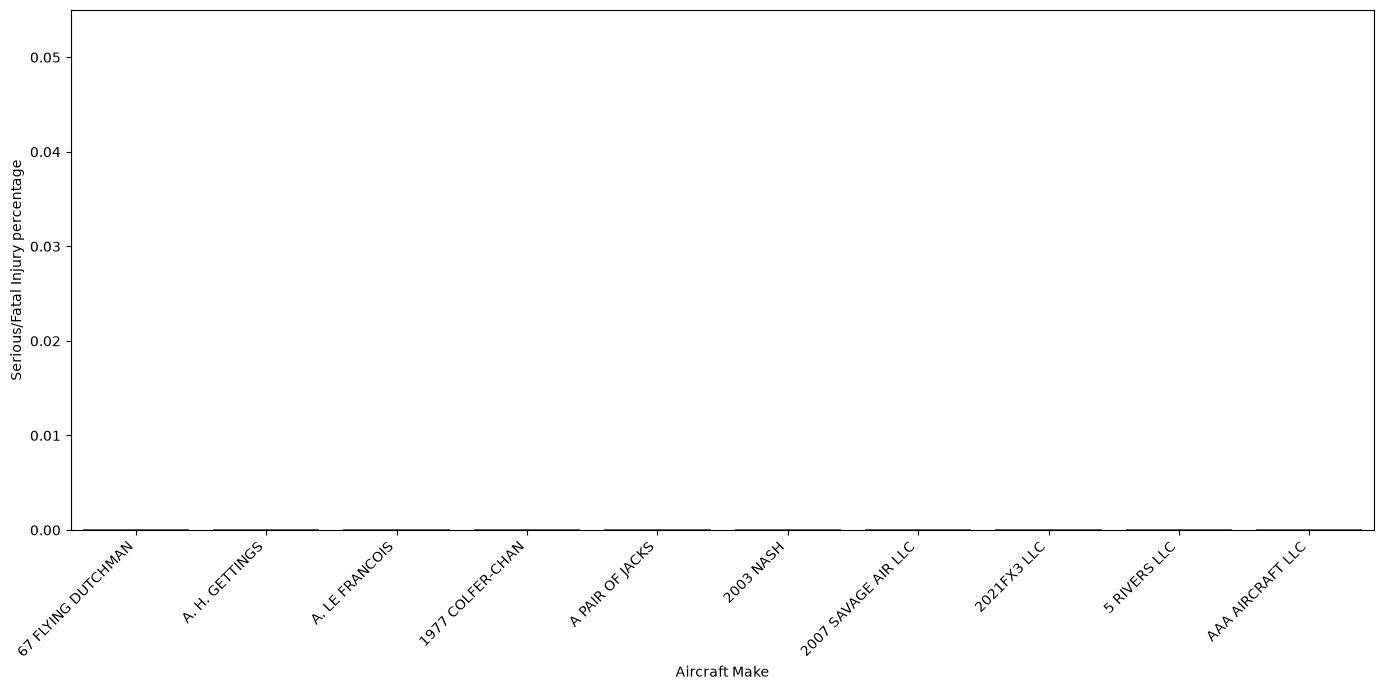

In [127]:
smaller_plane_sizes_means = aviation_data[aviation_data['Plane.Type'] == 'Smaller airplane']
smaller_plane_sizes_means_2 = smaller_plane_sizes_means.groupby('Make')['Total.Fatal.&.Serious.Injuries.Percentage'].mean().nsmallest(10).index
plot_data = smaller_plane_sizes_means[smaller_plane_sizes_means['Make'].isin(smaller_plane_sizes_means_2)]

plt.figure(figsize=(14, 7))

sns.violinplot(
    data = plot_data,
    x= 'Make',
    y= 'Total.Fatal.&.Serious.Injuries.Percentage',
    title = 'Distribution of injury rates in small planes'
)

plt.xlabel("Aircraft Make")
plt.ylabel("Serious/Fatal Injury percentage")
plt.ylim(0)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

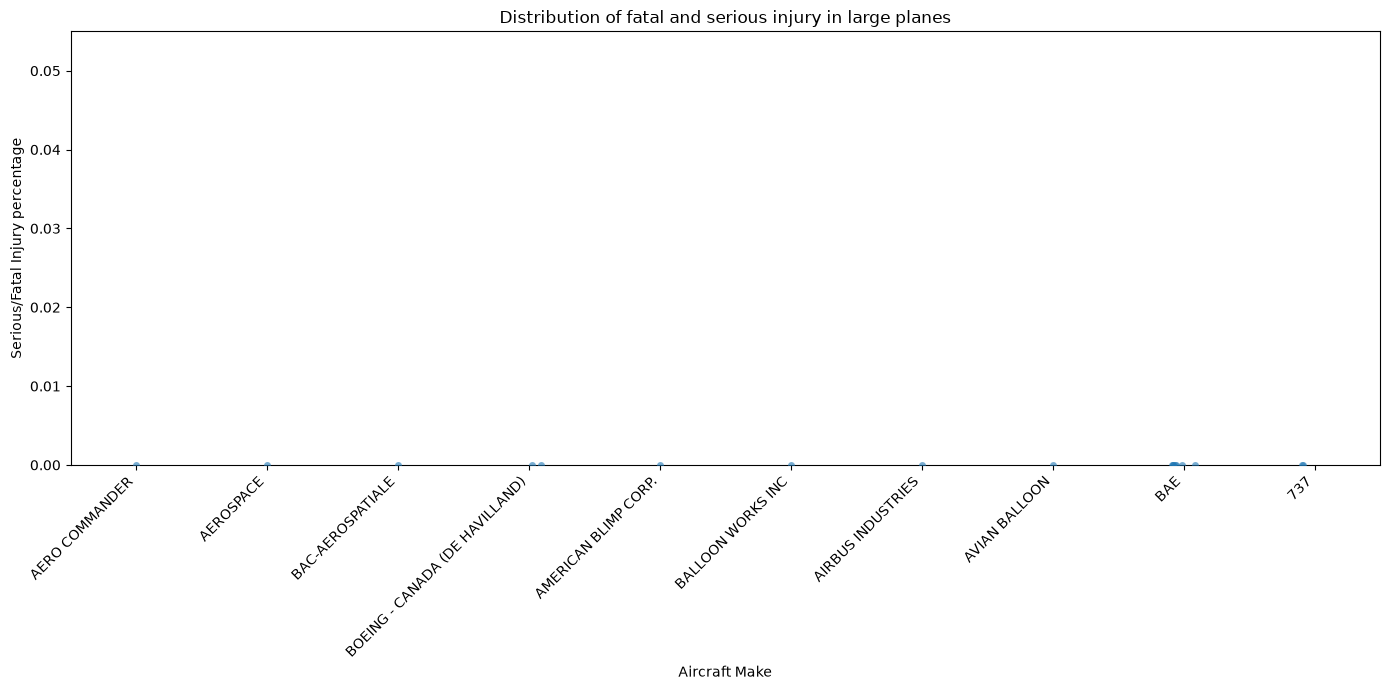

In [128]:
larger_plane_sizes_means = aviation_data[aviation_data['Plane.Type'] == 'Larger airplane']
larger_plane_sizes_means_2 = larger_plane_sizes_means.groupby('Make')['Total.Fatal.&.Serious.Injuries.Percentage'].mean().nsmallest(10).index
large_plane_plot_data = larger_plane_sizes_means[larger_plane_sizes_means["Make"].isin(larger_plane_sizes_means_2)]


plt.figure(figsize=(14, 7))

sns.stripplot(
    data = large_plane_plot_data,
    x = 'Make',
    y = 'Total.Fatal.&.Serious.Injuries.Percentage',
    jitter = True,
    alpha = 0.6
)
plt.title('Distribution of fatal and serious injury in large planes')
plt.xlabel("Aircraft Make")
plt.ylabel("Serious/Fatal Injury percentage")
plt.ylim(0)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

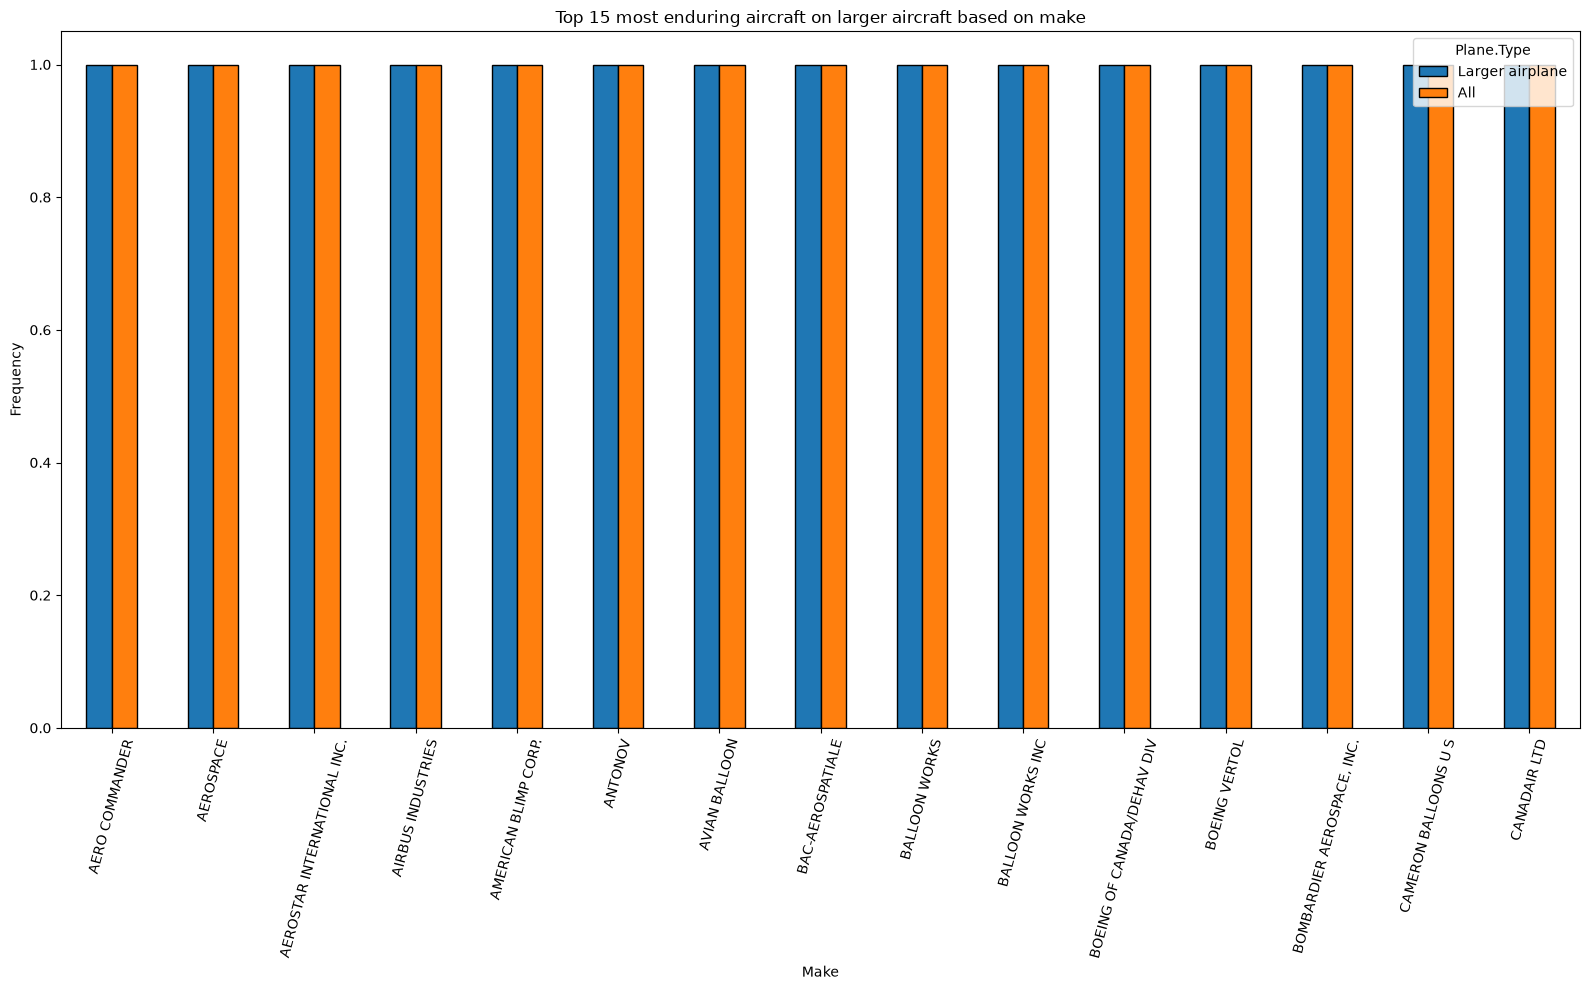

In [129]:
larger_plane_sizes_means = aviation_data[aviation_data['Plane.Type'] == 'Larger airplane']
larger_plane_pivot_table = larger_plane_sizes_means.pivot_table(
    index = 'Make',
    columns = 'Plane.Type',
    values = 'Aircraft.damage',
    aggfunc = 'count',
    fill_value = 0,
    margins=True
)
lowest_15_larger_aircraft = larger_plane_pivot_table.drop('All', errors='ignore').nsmallest(15,columns= 'All')

fig, ax = plt.subplots(figsize=(16,10))

lowest_15_larger_aircraft.plot(kind='bar', ax=ax, edgecolor='black')
ax.set_title('Top 15 most enduring aircraft on larger aircraft based on make')
ax.set_ylabel('Frequency')
ax.tick_params(axis='x', rotation=75)
plt.tight_layout()
plt.show()


Plane.Type                Smaller airplane  All
Make                                           
107.5 FLYING CORPORATION                 1    1
1200                                     1    1
177MF LLC                                1    1
1977 COLFER-CHAN                         1    1
1ST FTR GP                               1    1
2000 MCCOY                               1    1
2001 MCGIRL                              1    1
2003 NASH                                1    1
2007 SAVAGE AIR LLC                      1    1
3XTRIM                                   1    1
5 RIVERS LLC                             1    1
67 FLYING DUTCHMAN                       1    1
777                                      1    1
781569 INC                               1    1
85 MANISTA                               1    1


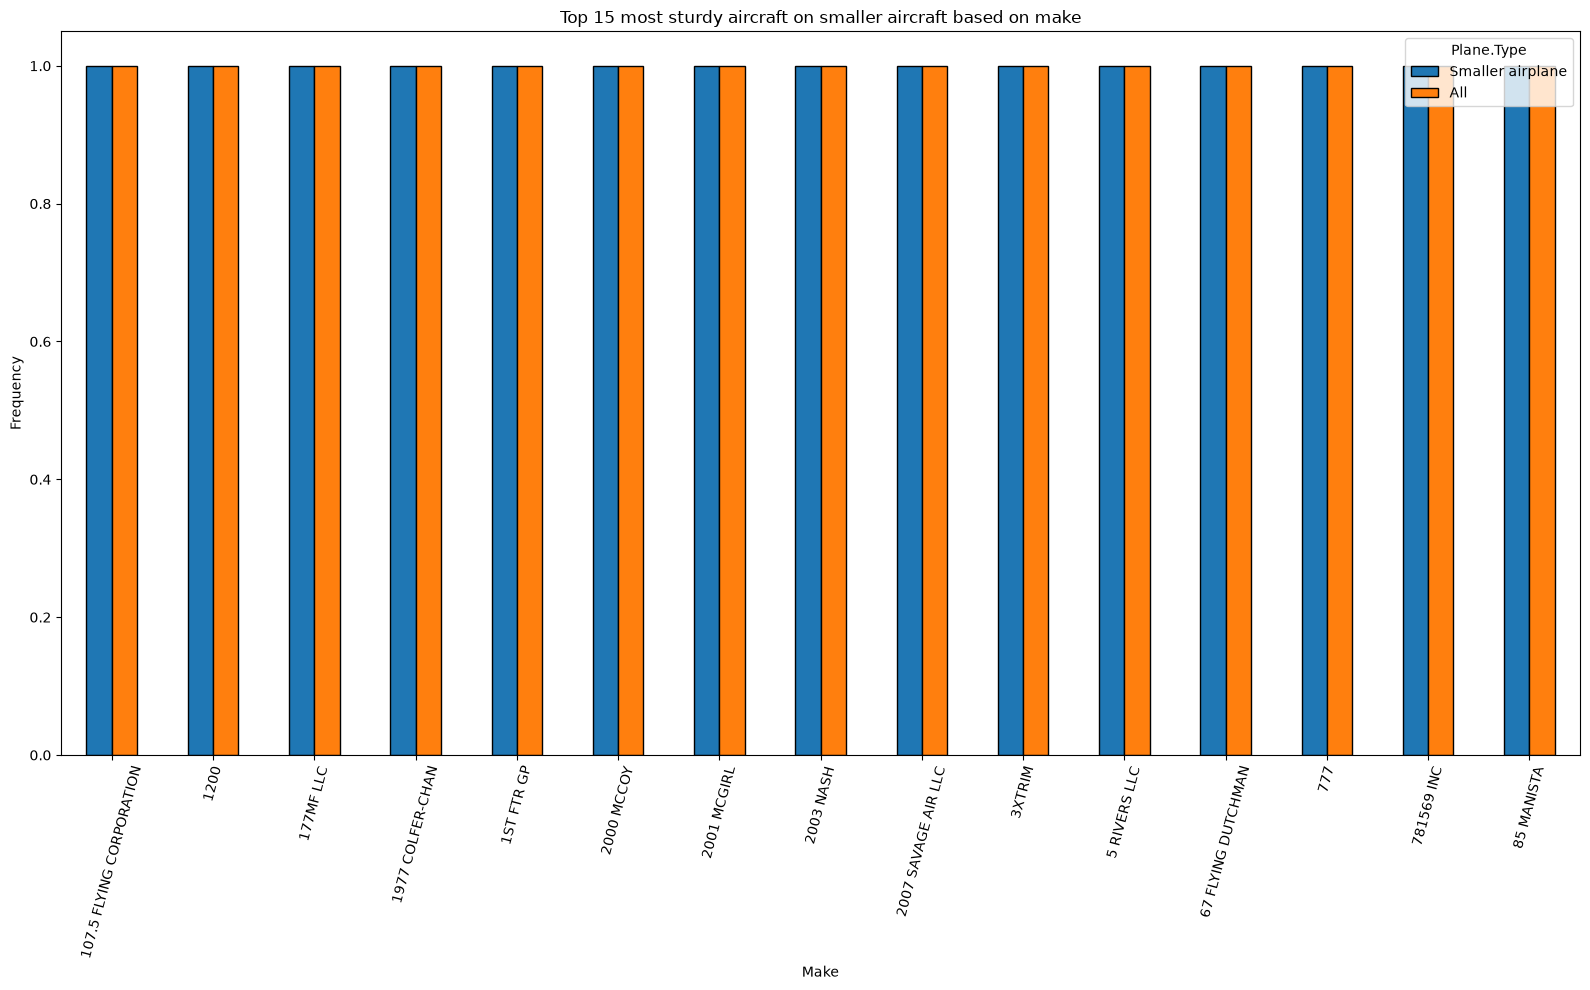

In [130]:
smaller_plane_sizes_means = aviation_data[aviation_data['Plane.Type'] == 'Smaller airplane']
smaller_plane_pivot_table = smaller_plane_sizes_means.pivot_table(
    index = 'Make',
    columns = 'Plane.Type',
    values = 'Aircraft.damage',
    aggfunc = 'count',
    fill_value = 0,
    margins=True
)
lowest_15_smaller_aircraft = smaller_plane_pivot_table.drop('All', errors='ignore').nsmallest(15,columns= 'All')
print(lowest_15_smaller_aircraft)

fig, ax = plt.subplots(figsize=(16,10))

lowest_15_smaller_aircraft.plot(kind='bar', ax=ax, edgecolor='black')
ax.set_title('Top 15 most sturdy aircraft on smaller aircraft based on make')
ax.set_ylabel('Frequency')
ax.tick_params(axis='x', rotation=75)
plt.tight_layout()
plt.show()



#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

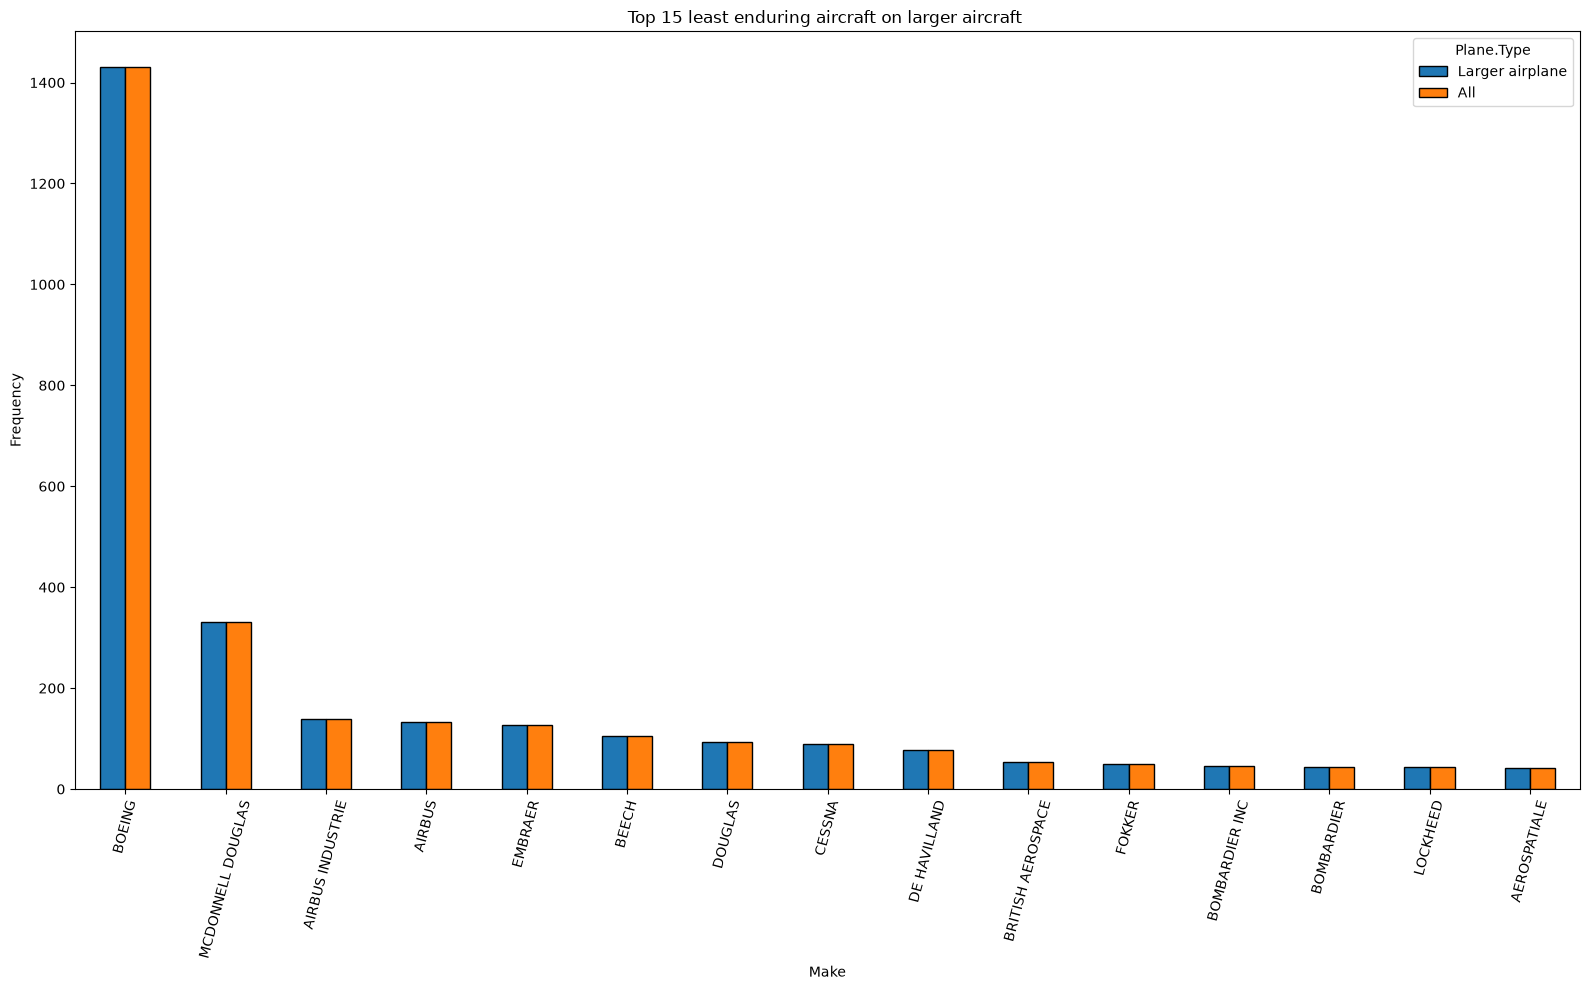

In [131]:
largest_15 = larger_plane_pivot_table.drop('All', errors='ignore').nlargest(15,columns= 'All')
print()

fig, ax = plt.subplots(figsize=(16,10))

largest_15.plot(kind='bar', ax=ax, edgecolor='black')
ax.set_title('Top 15 least enduring aircraft on larger aircraft ')
ax.set_ylabel('Frequency')
ax.tick_params(axis='x', rotation=75)
plt.tight_layout()
plt.show()

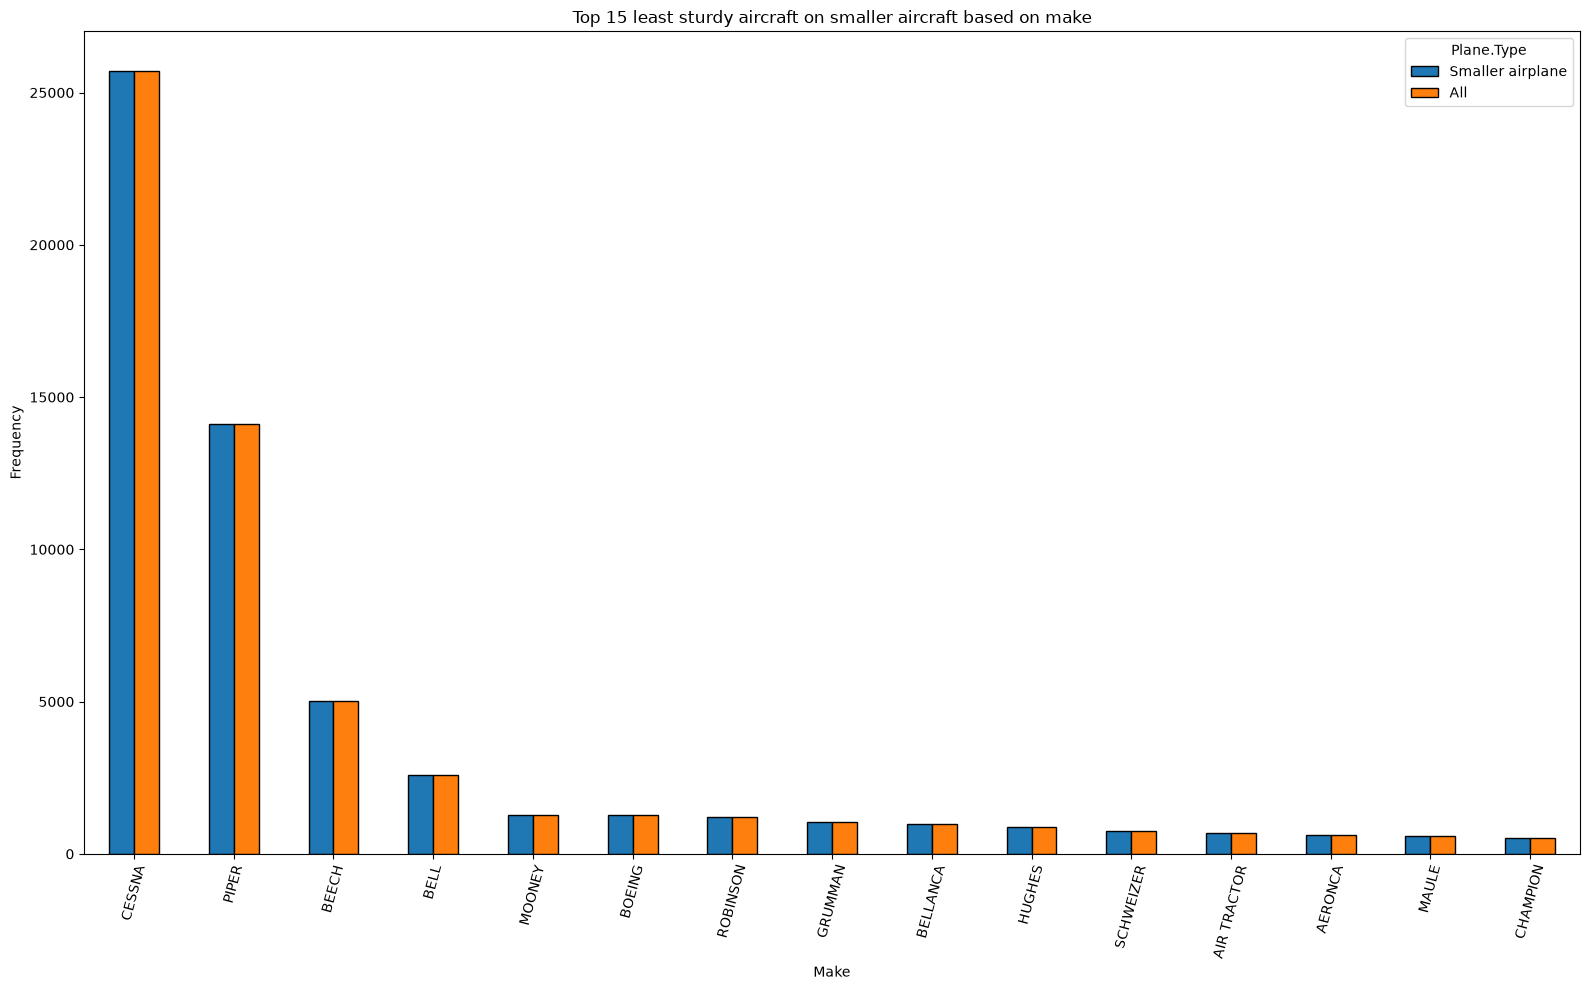

In [132]:
highest_15_smaller_aircraft = smaller_plane_pivot_table.drop('All', errors='ignore').nlargest(15,columns= 'All')


fig, ax = plt.subplots(figsize=(16,10))

highest_15_smaller_aircraft.plot(kind='bar', ax=ax, edgecolor='black')
ax.set_title('Top 15 least sturdy aircraft on smaller aircraft based on make')
ax.set_ylabel('Frequency')
ax.tick_params(axis='x', rotation=75)
plt.tight_layout()
plt.show()


- For the larger planes, Boeing has a high rate of aircraft damage where as there is a large number of aircraft that have only one time of aircraft damage. One should be careful when ensuring the Boeing planes as they seem to be more prone to damage.
- For smaller planes, Cessna seems to have a high rate of aircraft damage where as there is a large group of makes that have had one time of aircraft damage. 

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

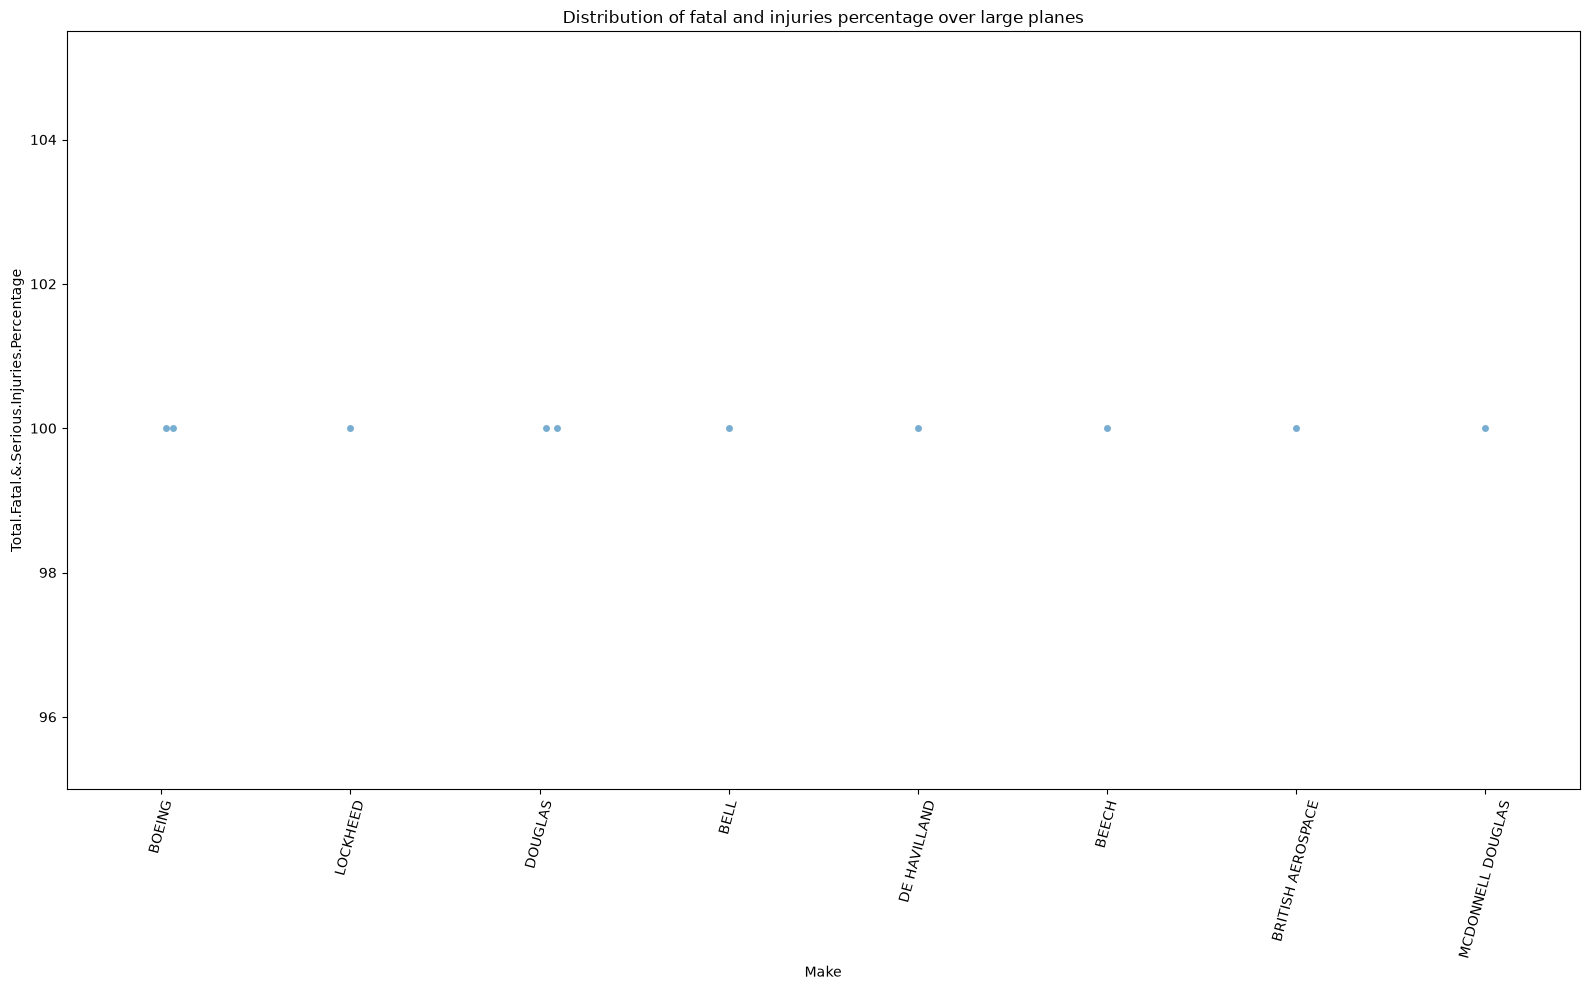

In [133]:
larger_plane_sizes_means_1 = larger_plane_sizes_means[['Make', 'Total.Fatal.&.Serious.Injuries.Percentage']].nlargest(10, columns='Total.Fatal.&.Serious.Injuries.Percentage')

fig , ax=plt.subplots(figsize=(16,10))

sns.stripplot(
    data = larger_plane_sizes_means_1,
    x = 'Make',
    y = 'Total.Fatal.&.Serious.Injuries.Percentage',
    jitter = True,
    alpha = 0.6
)
plt.title('Distribution of fatal and injuries percentage over large planes')
ax.tick_params(axis='x', rotation=75)
plt.ylim(95)
plt.tight_layout()
plt.show()

Text(0, 0.5, 'Fatal and Serious Injury percentage')

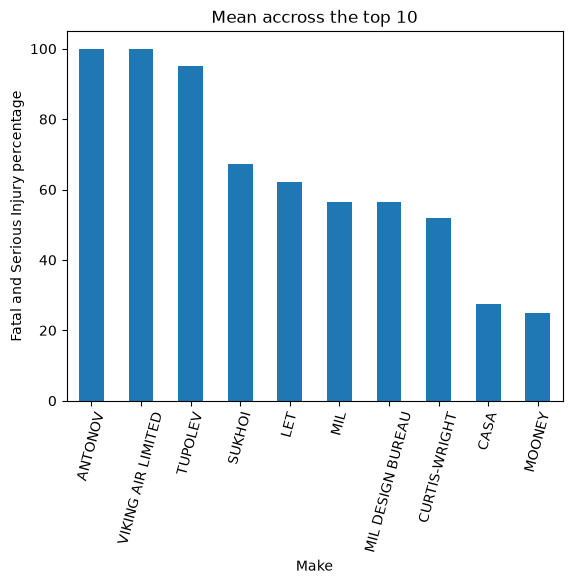

In [134]:
larger_plane_sizes_means = aviation_data[aviation_data['Plane.Type'] == 'Larger airplane']
larger_plane_sizes_means = larger_plane_sizes_means.groupby('Make')['Total.Fatal.&.Serious.Injuries.Percentage'].mean().nlargest(10)

larger_plane_sizes_means.plot(
    kind='bar',
    x='Make',
    y='Fatal and Serious injury percentage',
    title = 'Mean accross the top 10'
)
plt.xticks(rotation=75)
plt.xlabel('Make')
plt.ylabel('Fatal and Serious Injury percentage')

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

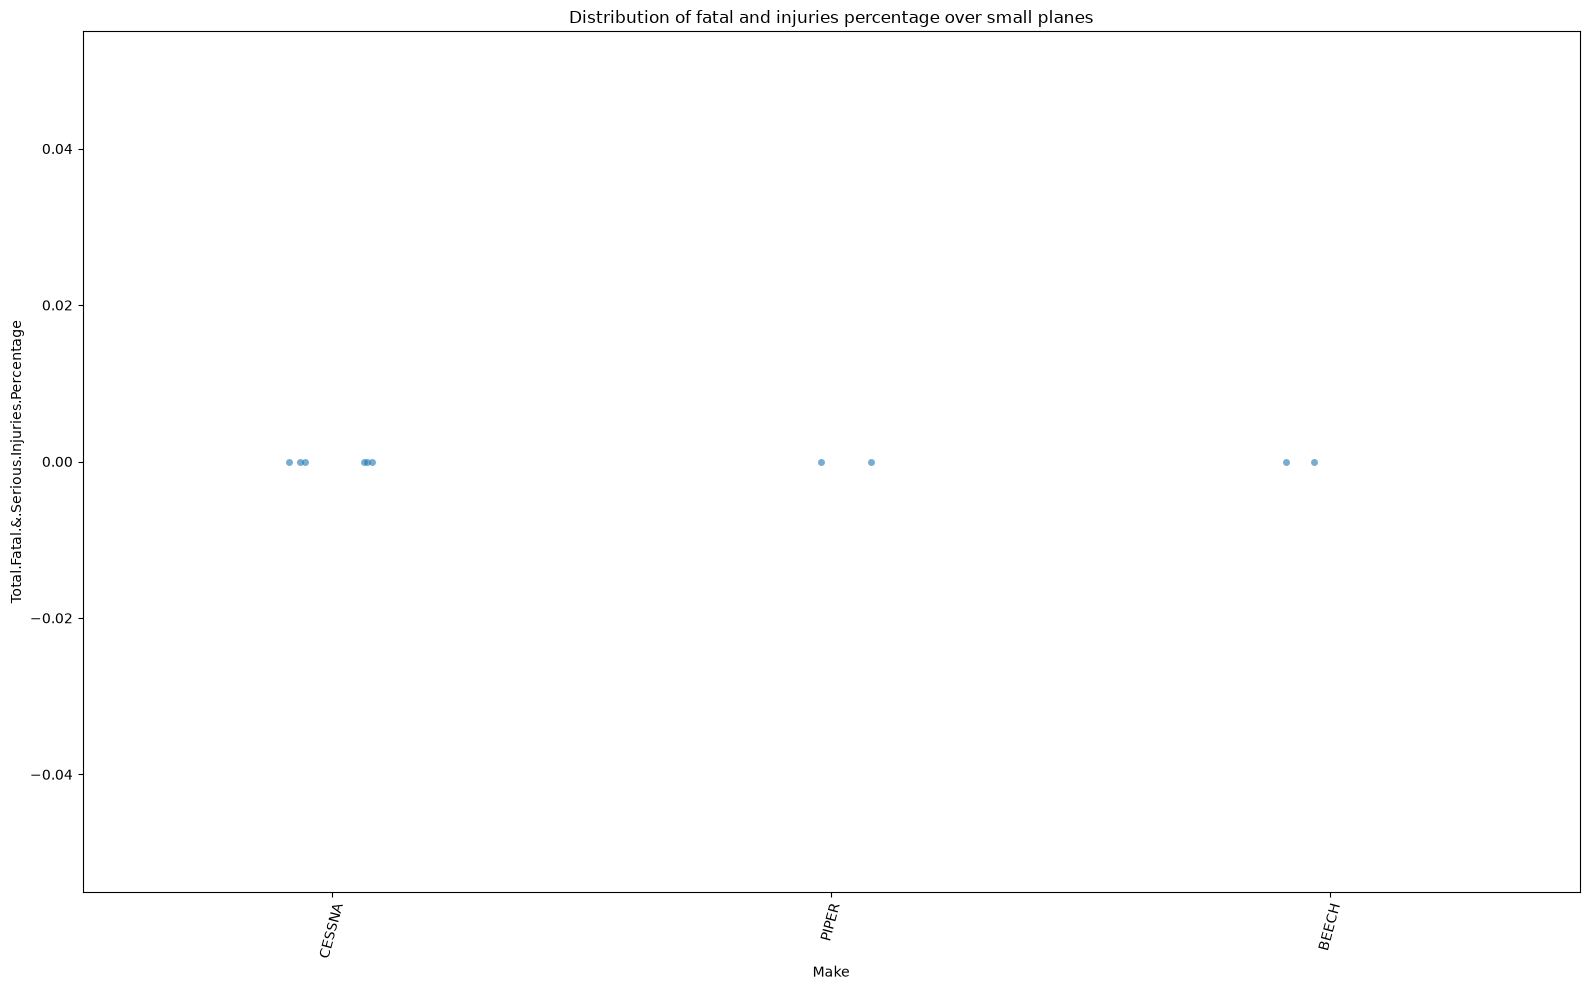

In [135]:
smaller_plane_sizes_means = aviation_data[aviation_data['Plane.Type'] == 'Smaller airplane']

least_small_plane_count = smaller_plane_sizes_means[['Make', 'Total.Fatal.&.Serious.Injuries.Percentage']].nsmallest(10, columns= 'Total.Fatal.&.Serious.Injuries.Percentage')
fig , ax=plt.subplots(figsize=(16,10))

sns.stripplot(
    data = least_small_plane_count,
    x = 'Make',
    y = 'Total.Fatal.&.Serious.Injuries.Percentage',
    jitter = True,
    alpha = 0.6
)
plt.title('Distribution of fatal and injuries percentage over small planes')
ax.tick_params(axis='x', rotation=75)

plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

- The small aircrafts with the least amount of fatal injuries are only 3 with Cessna Having 6 out of 10 parts.
- Boeing has a high rate of fatal and serious injuries of 100% therefore making it a hazadous deal when the premiums will not be set at a high.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

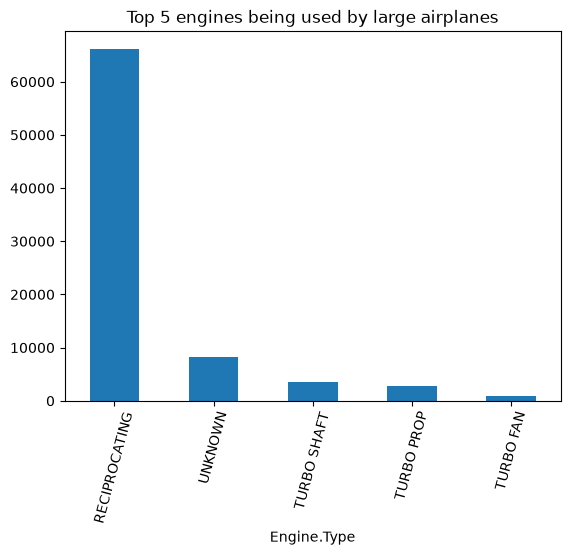

In [140]:
engine_types_large = aviation_data[aviation_data['Plane.Type'] == 'Larger airplane']
large_engine_count = engine_types['Engine.Type'].value_counts().nlargest(5)
large_engine_count.plot(
    kind = "bar",
    x = 'Engine.Type',
    y = 'count',
    title = 'Top 5 engines being used by large airplanes'
)
plt.xticks(rotation=75)
plt.show()

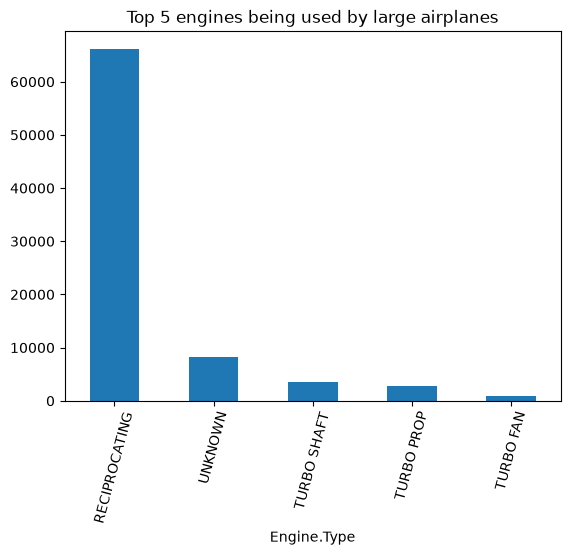

In [ ]:
engine_types_small = aviation_data[aviation_data['Plane.Type'] == 'Smaller airplane']
small_engine_count = engine_types['Engine.Type'].value_counts().nlargest(5)
small_engine_count.plot(
    kind = "bar",
    x = 'Engine.Type',
    y = 'count',
    title = 'Top 5 engines being used by small airplanes'
)
plt.xticks(rotation=75)
plt.show()

- The most popular engine type for large planes are turbo fan whereas for small planes is reciprocating.

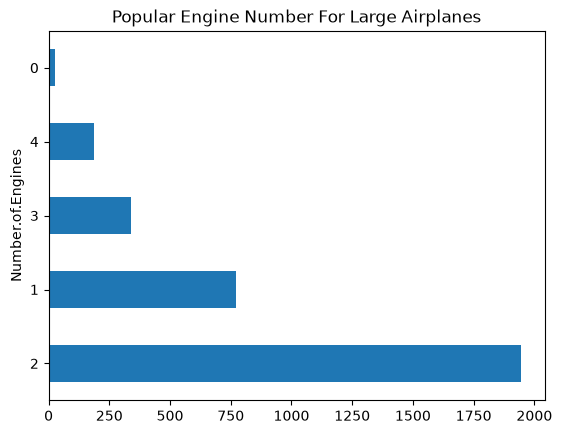

In [147]:
engine_number_large = aviation_data[aviation_data['Plane.Type'] == 'Larger airplane']
engine_number_large['Number.of.Engines'].value_counts().nlargest(5).plot(
    kind = 'barh',
    x = 'count',
    y = 'Number.of.Engines',
    title="Popular Engine Number For Large Airplanes"
)

plt.show()


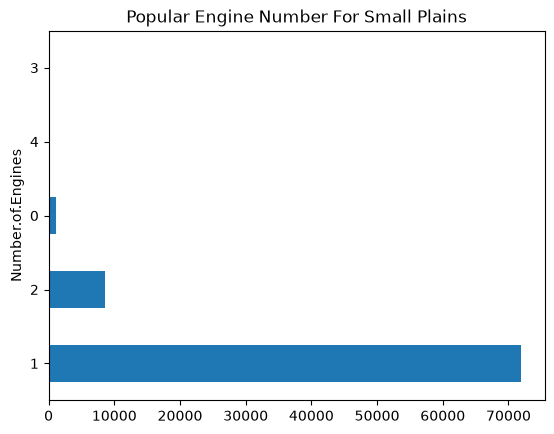

In [148]:
engine_number_small = aviation_data[aviation_data['Plane.Type'] == 'Smaller airplane']
engine_number_small['Number.of.Engines'].value_counts().nlargest(5).plot(
    kind = 'barh',
    x = 'count',
    y = 'Number.of.Engines',
    title="Popular Engine Number For Small Plains"
)

plt.show()


- A majority of Large airplanes use a 2-engine configuration.
- A majority of Small airplanes use a 1-engine configuration.